# Driver comparison — bubble charts of the environmental intensities by indicator

1 subplot per indicator, 2 bubbles per item of the X axis: M_dom+M_imp
(French products, size Y_dom) and M_row (imported products, size Y_imp).
See `planefr_lib.plot_bubble` for details.

Two steps:
1. Export of one Excel workbook per scenario (`bubble_data_by_indicator_<scenario>.xlsx`):
   1 sheet per indicator, sectors sorted according to the row chosen in B1
   (editable by hand in Excel), categories according to the `BRIDGE_SHEET` bridge.
2. Bubble charts read back from these workbooks: consumption categories or
   first n sectors, baseline alone or compared with a transition scenario.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

notebooks_dir = Path.cwd()
while not (notebooks_dir / "planefr_lib").exists() and notebooks_dir != notebooks_dir.parent:
    notebooks_dir = notebooks_dir.parent
if str(notebooks_dir) not in sys.path:
    sys.path.insert(0, str(notebooks_dir))

from planefr_lib import config, io
from planefr_lib.plot_bubble import export_indicator_tables_excel, load_indicator_tables_excel, plot_bubble_chart

Failed to read module file 'c:\Users\Arnaud\AppData\Local\Programs\Python\Python314\Lib\pydoc_data\topics.py' for module 'pydoc_data.topics': UnicodeDecodeError
Traceback (most recent call last):
  File "C:\Users\Arnaud\AppData\Roaming\Python\Python314\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "C:\Users\Arnaud\AppData\Roaming\Python\Python314\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
  File "c:\Users\Arnaud\AppData\Local\Programs\Python\Python314\Lib\importlib\__init__.py", line 88, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1398, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1371, in _find_and_load
  File "<frozen importlib._bootstrap>", line

## 1. Loading the common data

In [2]:

# Sheet of bridge_matrices.xlsx used to group the sectors by category
# (category columns of the Excel files, and hence of the bubble chart TYPE = "categories").
BRIDGE_SHEET = "M_split"   # "M": 5 categories; "M_split": 12 categories
bridge_m = io.load_bridge_m_matrix(BRIDGE_SHEET)

# Transition scenario compared with the baseline (folder name: S1, S2, S3, S4, TEND...)
COMPARISON_SCENARIO_NAME = "S1+"

# Scenario group to display: "no_SSP", "SSP1_2050", "SSP2_2050"... (see config.get_scenario_groups())
SCENARIO_GROUP = "SSP_all"
cf_df = io.load_characterization_factors(SCENARIO_GROUP)
scenario_folders = config.get_scenario_folders(exclude_2019=True, scenario_group=SCENARIO_GROUP)
reference_folder = scenario_folders[config.REFERENCE_SCENARIO_IDX]
comparison_folder = next((f for f in scenario_folders if f.name == COMPARISON_SCENARIO_NAME), None)
if comparison_folder is None:
    raise ValueError(
        f"Scenario '{COMPARISON_SCENARIO_NAME}' not found among {[f.name for f in scenario_folders]}"
    )
print(f"Reference scenario: {reference_folder.name} | compared with: {comparison_folder.name}")
print(f"Bridge {BRIDGE_SHEET}: {bridge_m.shape}, categories = {list(bridge_m.columns)}")

Reference scenario: 2015 | compared with: S1+
Bridge M_split: (200, 9), categories = ['Vegetal products', 'Animal products', 'Sugar, Beverages & Tobacco', 'Housing', 'Mobility', 'Textiles', 'Final goods nec', 'Hotel & restaurant', 'Final services']


c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:140: UserWarning: Group 'SSP_all' does not contain Base_year_2015: the reference scenario (REFERENCE_SCENARIO_IDX) will be the first one in alphabetical order.
  warnings.warn(


## 2. Excel export of the data by indicator

One workbook per scenario, 1 sheet per indicator: 1 column per sector
(200 products) + 1 column per category of the `BRIDGE_SHEET` bridge, 1 row per
data item (M_imp, M_dom, M_row, Y_imp, Y_dom, M*Y products). Sectors then
categories sorted in decreasing order of the row chosen in B1.

`OVERWRITE_EXCEL = False`: an existing workbook is not regenerated, to keep
the sort rows (B1) edited by hand in Excel -- unless its categories no longer
match `BRIDGE_SHEET` or it comes from an earlier format. Set to `True` to
recompute everything from the MRIO data.

In [3]:
OVERWRITE_EXCEL = True


def excel_is_up_to_date(path):
    """True if the workbook has the categories of the current bridge and the
    current format (categories sorted by formulas); otherwise it is regenerated."""
    sheets = load_indicator_tables_excel(path)
    expected = [str(c) for c in bridge_m.columns]
    return bool(sheets) and all(s["categories"] == expected and s["categories_sorted"] for s in sheets.values())


excel_paths = {}
for folder in [reference_folder, comparison_folder]:
    path = config.FIGURES_DIR / f"bubble_data_by_indicator_{folder.name}.xlsx"
    if OVERWRITE_EXCEL or not path.exists() or not excel_is_up_to_date(path):
        export_indicator_tables_excel(folder, cf_df, bridge_m, path)
        print(f"Excel table saved: {path}")
    else:
        print(f"Existing Excel table kept: {path}")
    excel_paths[folder.name] = path

base_excel = excel_paths[reference_folder.name]
comparison_excel = excel_paths[comparison_folder.name]

Excel table saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\bubble_data_by_indicator_2015.xlsx
Excel table saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\bubble_data_by_indicator_S1+.xlsx


## 3. Bubble charts (read back from the Excel workbooks)

Parameters of `plot_bubble_chart`:
- `type`: `"categories"` (consumption categories) or `"products"` (sectors),
  in both cases in decreasing order of the sort row chosen in B1 of each
  Excel sheet;
- `n`: number of sectors displayed if `type="products"` (the first `n`);
- `scenarios`: `False` = baseline alone, `True` = comparison with `comparison_excel`
  (columns and order taken from the ranking of the baseline).

Figure saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\bubble_chart_2015_categories.png


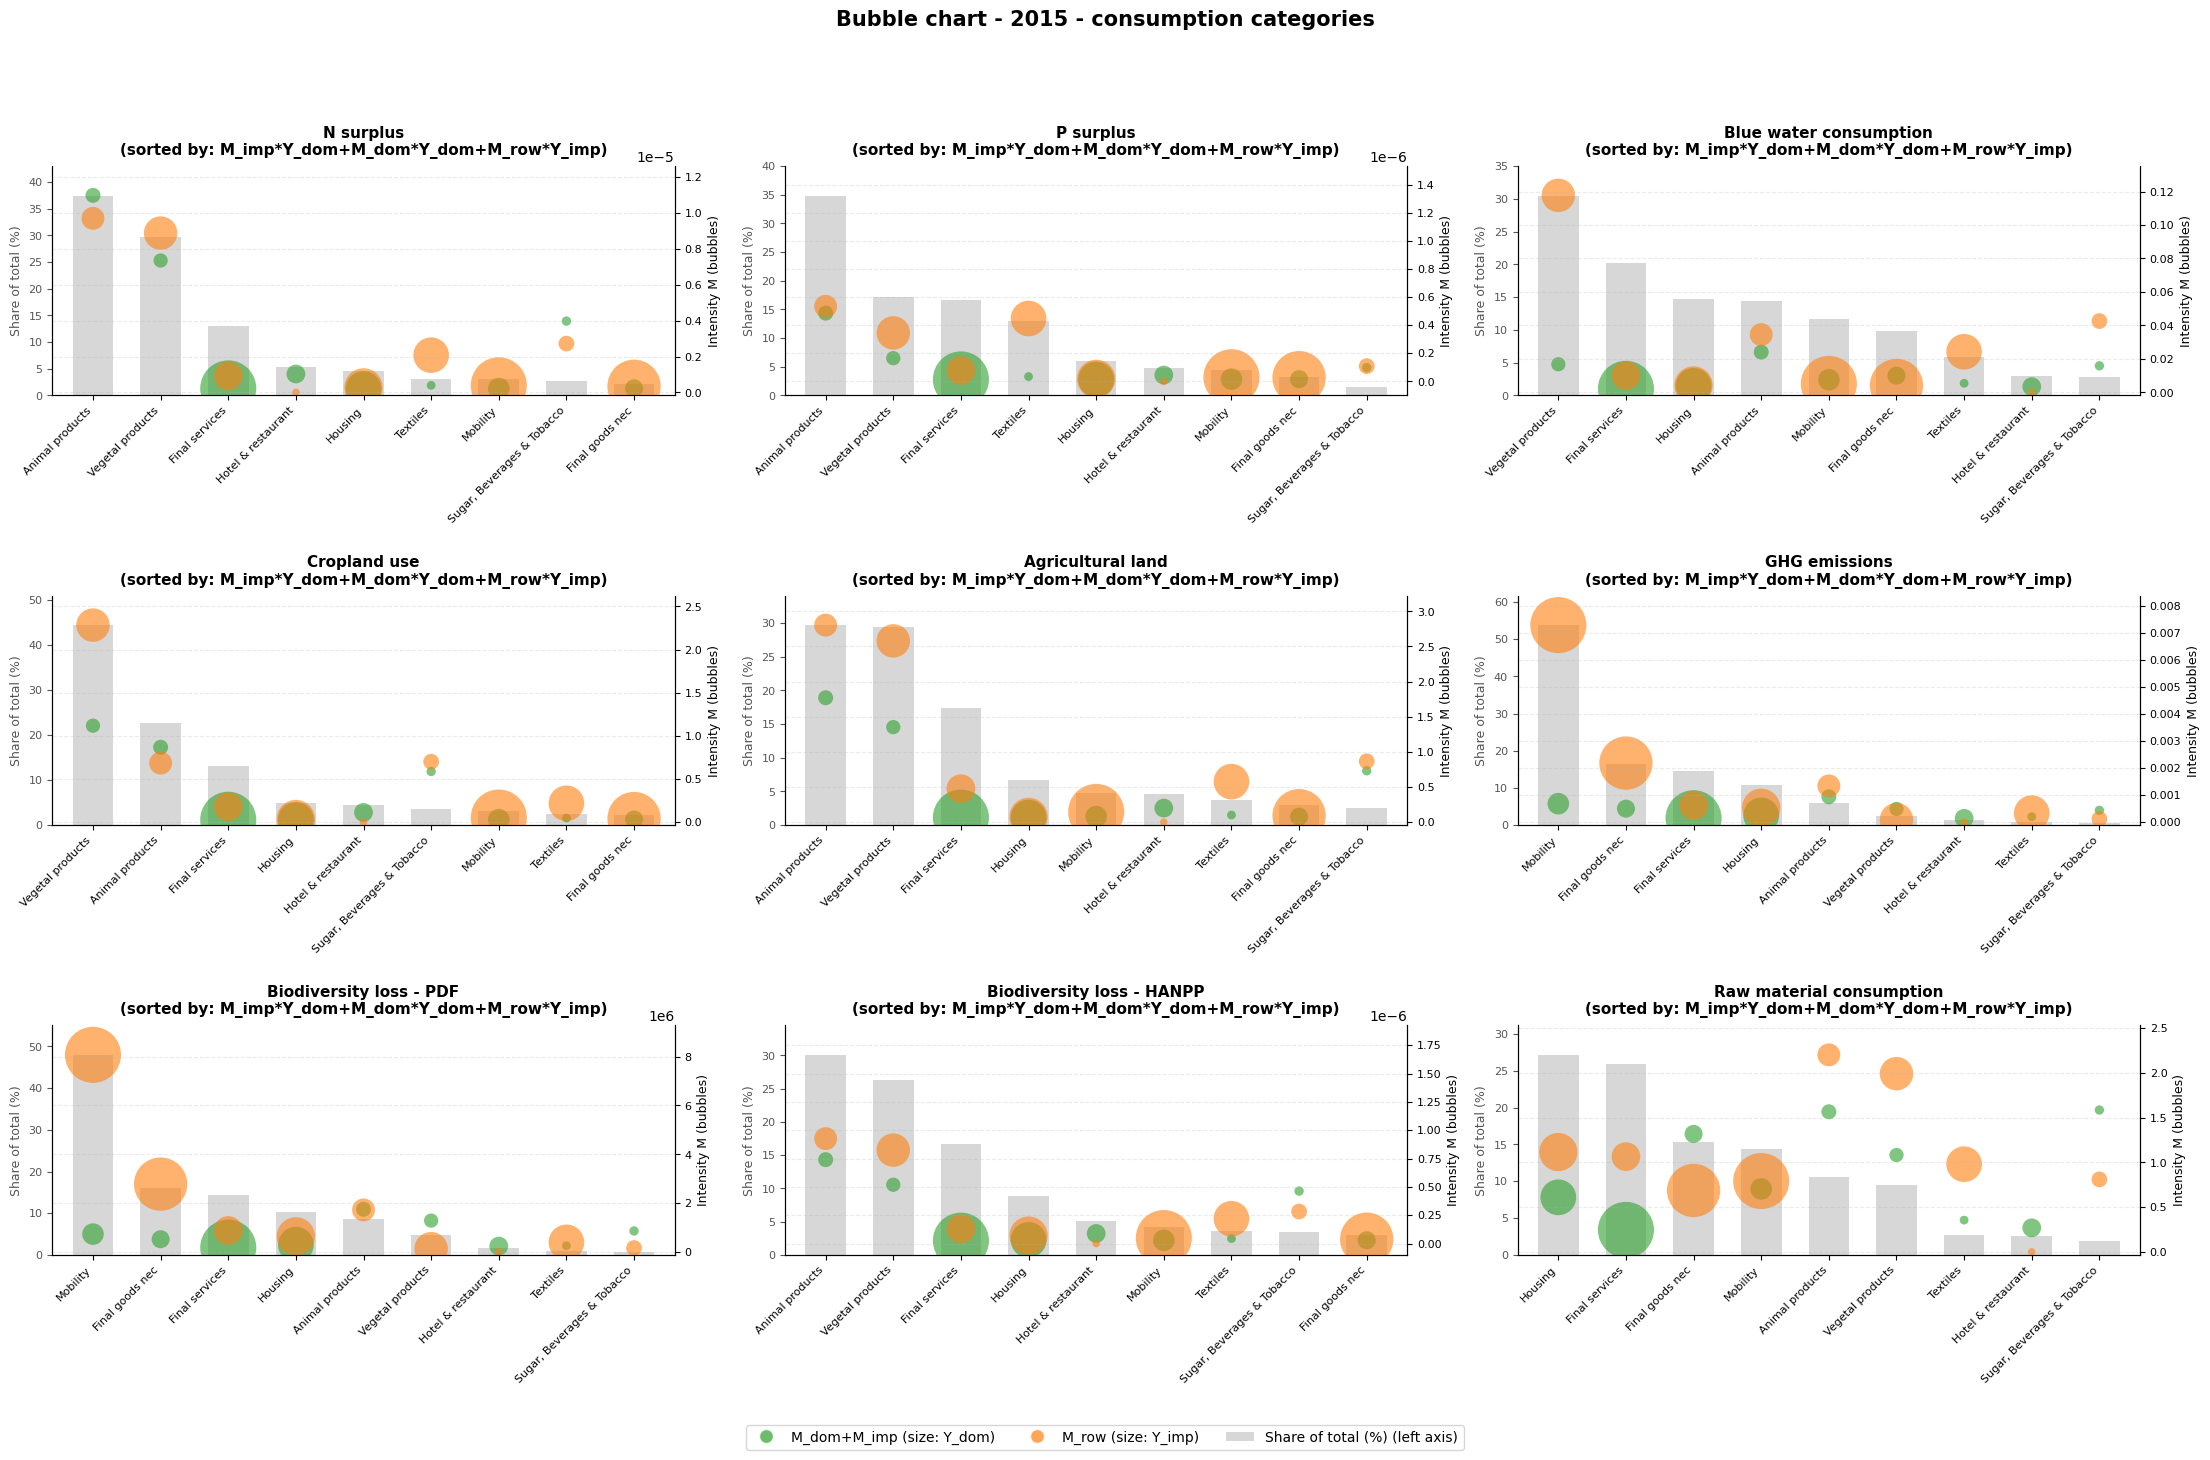

In [5]:
TYPE = "categories"   # "categories" or "products"
N = 5          # number of sectors if TYPE = "products"
SCENARIOS = False     # True: comparison with the transition scenario

fig, _ = plot_bubble_chart(base_excel, type=TYPE, n=N, scenarios=SCENARIOS,
                           comparison_excel_path=comparison_excel)

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
suffix = TYPE if TYPE == "categories" else f"top{N}_products"
scope = f"{reference_folder.name}_vs_{comparison_folder.name}" if SCENARIOS else reference_folder.name
output_path = config.FIGURES_DIR / f"bubble_chart_{scope}_{suffix}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Figure saved: {output_path}")